# ApnoAI Task 2 — Train Your First Model
## Iris Flower Classification with a Decision Tree

This project used the Iris dataset to build and evaluate a machine-learning classifier. The workflow covered data inspection, a reproducible train/test split, model training, test-size experiments, a confusion matrix, and a comparison with a Random Forest classifier.

**Learning objectives**
- Separate training data from unseen test data to evaluate generalization.
- Train a Decision Tree classifier and compare training accuracy with test accuracy.
- Examine how changing the test-set proportion affected the evaluation.
- Interpret a confusion matrix instead of relying on accuracy alone.
- Compare a second model using the same held-out test samples.

The experiments used a fixed random seed so that the split and results could be reproduced.

## 1. Import libraries

The required Python libraries were imported for data handling, model training, evaluation, and visualization. The project used scikit-learn's built-in Iris dataset, so no external dataset download was required.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load and inspect the Iris dataset

The Iris dataset contained measurements of 150 flowers. Each sample had four numerical features: sepal length, sepal width, petal length, and petal width. The target represented one of three species: Setosa, Versicolor, or Virginica.

In [ ]:
iris = load_iris(as_frame=True)
X = iris.data.copy()
y = iris.target.copy()
class_names = list(iris.target_names)
feature_names = list(iris.feature_names)

df = X.copy()
df["species"] = y.map(dict(enumerate(class_names)))

print(f"Dataset rows: {X.shape[0]}")
print(f"Number of features: {X.shape[1]}")
print(f"Number of classes: {len(class_names)}")
print("\nFeature names:")
print(feature_names)
print("\nClass distribution:")
print(df["species"].value_counts().reindex(class_names))
print("\nFirst five rows:")
display(df.head())

Dataset rows: 150
Number of features: 4
Number of classes: 3

Feature names:
['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']

Class distribution:
species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64

First five rows:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


### Initial observations

The dataset shape and class distribution were inspected before training. Checking the data first helped confirm the number of samples, the input features, and the target classes that the model was expected to predict.

In [ ]:
print("Dataset dimensions:", df.shape)
print("\nMissing values per column:")
display(df.isna().sum().to_frame("missing_values"))

print("\nSummary statistics for the four features:")
display(X.describe().T)

Dataset dimensions: (150, 5)

Missing values per column:


,missing_values
sepal length (cm),0
sepal width (cm),0
petal length (cm),0
petal width (cm),0
species,0



Summary statistics for the four features:


,count,mean,std,min,25%,50%,75%,max
sepal length (cm),150.0,5.843,0.828,4.3,5.1,5.80,6.4,7.9
sepal width (cm),150.0,3.057,0.436,2.0,2.8,3.00,3.3,4.4
petal length (cm),150.0,3.758,1.765,1.0,1.6,4.35,5.1,6.9
petal width (cm),150.0,1.199,0.762,0.1,0.3,1.30,1.8,2.5


## 3. Split the data into training and test sets

The data was divided into 80% training samples and 20% test samples. The classifier learned from the training set, while the test set was held back for evaluation. Stratification preserved the class proportions in both sets, and `random_state=42` made the split reproducible.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training samples: {len(X_train)}")
print(f"Test samples: {len(X_test)}")
print(f"Training proportion: {len(X_train) / len(X):.1%}")
print(f"Test proportion: {len(X_test) / len(X):.1%}")
print("\nTraining class counts:")
print(y_train.value_counts().sort_index().rename(index=dict(enumerate(class_names))))
print("\nTest class counts:")
print(y_test.value_counts().sort_index().rename(index=dict(enumerate(class_names))))

Training samples: 120
Test samples: 30
Training proportion: 80.0%
Test proportion: 20.0%

Training class counts:
target
setosa        40
versicolor    40
virginica     40
Name: count, dtype: int64

Test class counts:
target
setosa        10
versicolor    10
virginica     10
Name: count, dtype: int64


## 4. Train the Decision Tree model

A Decision Tree classifier was trained on the training samples. The model was limited to a maximum depth of four to keep the learned tree interpretable. Training and test accuracy were calculated separately; test accuracy was the more relevant estimate of performance on unseen samples.

In [ ]:
decision_tree = DecisionTreeClassifier(
    max_depth=4,
    random_state=RANDOM_STATE
)
decision_tree.fit(X_train, y_train)

y_train_pred = decision_tree.predict(X_train)
y_test_pred = decision_tree.predict(X_test)

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_test_pred)

print(f"Training accuracy: {train_accuracy:.3f} ({train_accuracy:.1%})")
print(f"Test accuracy:     {test_accuracy:.3f} ({test_accuracy:.1%})")
print(f"Train-test accuracy gap: {train_accuracy - test_accuracy:+.3f}")

Training accuracy: 0.992 (99.2%)
Test accuracy:     0.933 (93.3%)
Train-test accuracy gap: +0.058


### Interpreting the accuracy

Accuracy is the proportion of predictions that matched the true labels. A small difference between training and test accuracy can indicate that performance was similar on the training and held-out samples, although it does not prove that a model will perform equally well on every future dataset. A much higher training score than test score can be a sign of overfitting.

In [ ]:
print("Classification report on the held-out test set:")
print(classification_report(
    y_test,
    y_test_pred,
    labels=[0, 1, 2],
    target_names=class_names,
    zero_division=0
))

Classification report on the held-out test set:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



### Visualize the learned Decision Tree

The tree plot displayed the sequence of feature-based decisions learned from the training data. Each node showed a split condition and the class counts represented at that node.

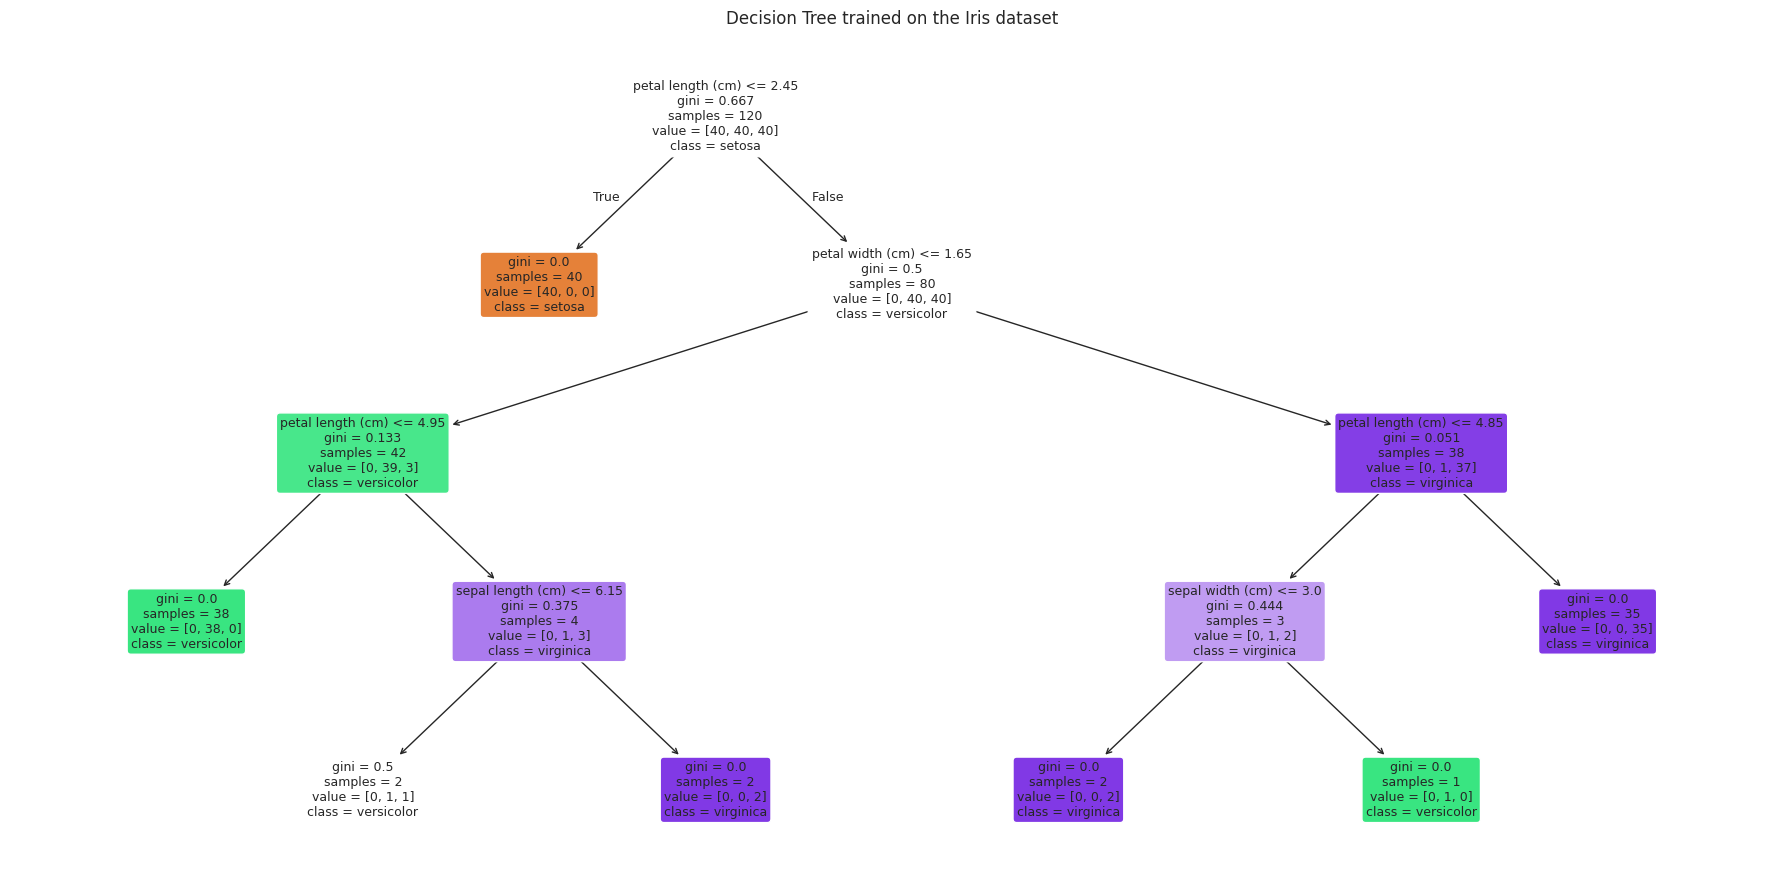

In [ ]:
plt.figure(figsize=(18, 9))
plot_tree(
    decision_tree,
    feature_names=feature_names,
    class_names=class_names,
    filled=True,
    rounded=True,
    proportion=False,
    impurity=True,
    fontsize=9
)
plt.title("Decision Tree trained on the Iris dataset")
plt.tight_layout()
plt.show()

## 5. Experiment with different `test_size` values

The experiment was repeated with test proportions of 0.1, 0.2, 0.4, and 0.5. For each split, a new Decision Tree was trained and evaluated. The same random seed and stratification setting were used for a fair, reproducible comparison.

A smaller test set left more samples for training but made the test accuracy more sensitive to individual predictions. A larger test set gave more samples for evaluation but left fewer samples for learning. Because this dataset was small, the reported accuracy could vary across splits.

In [ ]:
test_sizes = [0.1, 0.2, 0.4, 0.5]
experiment_rows = []

for size in test_sizes:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y,
        test_size=size,
        random_state=RANDOM_STATE,
        stratify=y
    )
    model = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
    model.fit(X_tr, y_tr)

    experiment_rows.append({
        "test_size": size,
        "train_samples": len(X_tr),
        "test_samples": len(X_te),
        "training_accuracy": accuracy_score(y_tr, model.predict(X_tr)),
        "test_accuracy": accuracy_score(y_te, model.predict(X_te))
    })

experiment_results = pd.DataFrame(experiment_rows)
display(
    experiment_results.style.format({
        "test_size": "{:.1f}",
        "training_accuracy": "{:.1%}",
        "test_accuracy": "{:.1%}"
    })
)

,test_size,train_samples,test_samples,training_accuracy,test_accuracy
0,0.1,135,15,99.3%,86.7%
1,0.2,120,30,99.2%,93.3%
2,0.4,90,60,98.9%,95.0%
3,0.5,75,75,98.7%,88.0%


### Compare the experiment results

The chart compared test accuracy across the four split sizes. The scores were interpreted together with the number of test samples; the highest score alone was not treated as proof that a split was best. With a small dataset, one or two changed predictions can noticeably affect accuracy.

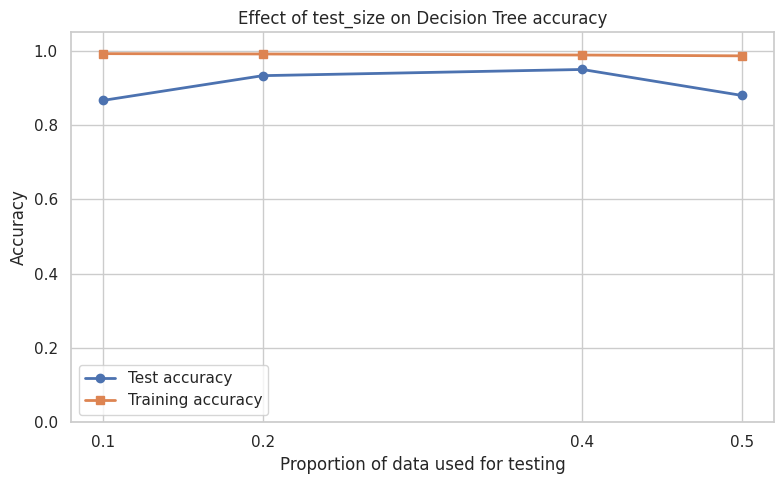

Experiment summary:
test_size=0.1: 135 train, 15 test, train accuracy=99.3%, test accuracy=86.7%
test_size=0.2: 120 train, 30 test, train accuracy=99.2%, test accuracy=93.3%
test_size=0.4: 90 train, 60 test, train accuracy=98.9%, test accuracy=95.0%
test_size=0.5: 75 train, 75 test, train accuracy=98.7%, test accuracy=88.0%


In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(
    experiment_results["test_size"],
    experiment_results["test_accuracy"],
    marker="o",
    linewidth=2,
    label="Test accuracy"
)
plt.plot(
    experiment_results["test_size"],
    experiment_results["training_accuracy"],
    marker="s",
    linewidth=2,
    label="Training accuracy"
)
plt.xticks(test_sizes)
plt.ylim(0, 1.05)
plt.xlabel("Proportion of data used for testing")
plt.ylabel("Accuracy")
plt.title("Effect of test_size on Decision Tree accuracy")
plt.legend()
plt.tight_layout()
plt.show()

print("Experiment summary:")
for row in experiment_results.itertuples(index=False):
    print(
        f"test_size={row.test_size:.1f}: "
        f"{row.train_samples} train, {row.test_samples} test, "
        f"train accuracy={row.training_accuracy:.1%}, "
        f"test accuracy={row.test_accuracy:.1%}"
    )

## 6. Confusion matrix

The confusion matrix compared actual classes with predicted classes for the original 20% test split. Rows represented actual species and columns represented predicted species. Values on the diagonal represented correct predictions; off-diagonal values represented mistakes.

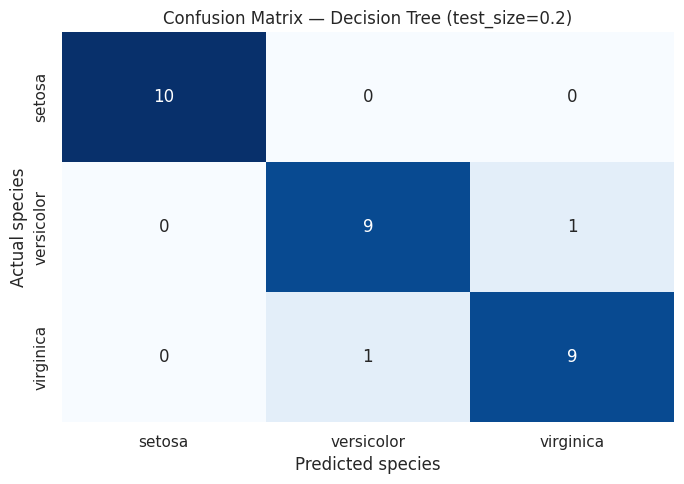

Confusion matrix (rows = actual, columns = predicted):
[[10  0  0]
 [ 0  9  1]
 [ 0  1  9]]

Correct predictions on the test set: 28 out of 30
Incorrect predictions on the test set: 2


In [ ]:
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1, 2])

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names,
    cbar=False
)
plt.xlabel("Predicted species")
plt.ylabel("Actual species")
plt.title("Confusion Matrix — Decision Tree (test_size=0.2)")
plt.tight_layout()
plt.show()

print("Confusion matrix (rows = actual, columns = predicted):")
print(cm)
print("\nCorrect predictions on the test set:", int(np.trace(cm)), "out of", len(y_test))
print("Incorrect predictions on the test set:", int(len(y_test) - np.trace(cm)))

## 7. Bonus: Compare a Random Forest model (+10 XP)

A Random Forest classifier was trained using the same training and test split. It combined multiple decision trees, whereas the first model used one tree. Both models were evaluated on the same held-out samples so their scores could be compared directly.

,model,training_accuracy,test_accuracy
0,Decision Tree,99.2%,93.3%
1,Random Forest,100.0%,90.0%


<Figure size 800x500 with 0 Axes>

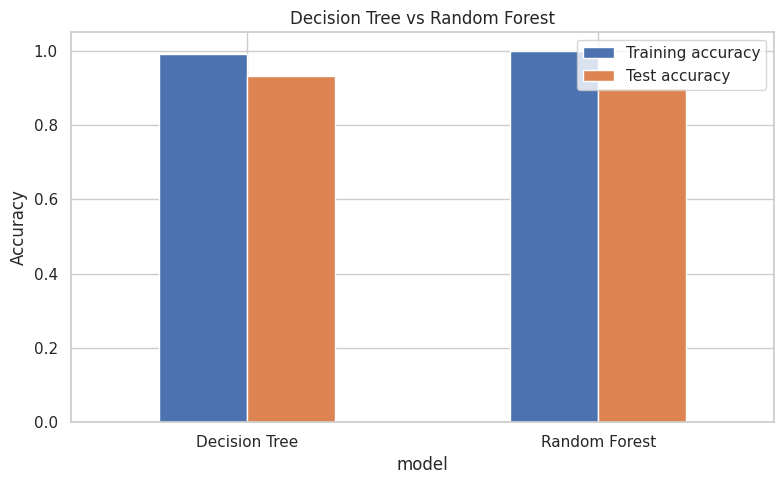

In [ ]:
random_forest = RandomForestClassifier(
    n_estimators=200,
    random_state=RANDOM_STATE
)
random_forest.fit(X_train, y_train)

rf_train_pred = random_forest.predict(X_train)
rf_test_pred = random_forest.predict(X_test)

comparison = pd.DataFrame([
    {
        "model": "Decision Tree",
        "training_accuracy": accuracy_score(y_train, y_train_pred),
        "test_accuracy": accuracy_score(y_test, y_test_pred)
    },
    {
        "model": "Random Forest",
        "training_accuracy": accuracy_score(y_train, rf_train_pred),
        "test_accuracy": accuracy_score(y_test, rf_test_pred)
    }
])

display(comparison.style.format({
    "training_accuracy": "{:.1%}",
    "test_accuracy": "{:.1%}"
}))

plt.figure(figsize=(8, 5))
comparison_plot = comparison.set_index("model")[["training_accuracy", "test_accuracy"]]
comparison_plot.plot(kind="bar", ylim=(0, 1.05), figsize=(8, 5))
plt.ylabel("Accuracy")
plt.title("Decision Tree vs Random Forest")
plt.xticks(rotation=0)
plt.legend(["Training accuracy", "Test accuracy"])
plt.tight_layout()
plt.show()

### Bonus model interpretation

The models were compared using both training and test accuracy. A Random Forest can reduce the variance of a single tree by averaging predictions across many trees, but it is not guaranteed to score higher on every small test split. Test performance and the size of the train-test gap were considered together.

In [ ]:
dt_test = accuracy_score(y_test, y_test_pred)
rf_test = accuracy_score(y_test, rf_test_pred)
dt_gap = accuracy_score(y_train, y_train_pred) - dt_test
rf_gap = accuracy_score(y_train, rf_train_pred) - rf_test

print(f"Decision Tree test accuracy: {dt_test:.1%}; train-test gap: {dt_gap:+.1%}")
print(f"Random Forest test accuracy: {rf_test:.1%}; train-test gap: {rf_gap:+.1%}")

if rf_test > dt_test:
    print("On this split, Random Forest achieved higher test accuracy.")
elif rf_test < dt_test:
    print("On this split, Decision Tree achieved higher test accuracy.")
else:
    print("Both models achieved the same test accuracy on this split.")

Decision Tree test accuracy: 93.3%; train-test gap: +5.8%
Random Forest test accuracy: 90.0%; train-test gap: +10.0%
On this split, Decision Tree achieved higher test accuracy.


## 8. Three key insights

The three insights below were generated from the experiment outputs above rather than from a preselected accuracy claim. They were intended to summarize the actual results of this run.

In [ ]:
best_row = experiment_results.loc[experiment_results["test_accuracy"].idxmax()]
worst_row = experiment_results.loc[experiment_results["test_accuracy"].idxmin()]
cm_off_diagonal = int(cm.sum() - np.trace(cm))
most_confused = None

if cm_off_diagonal > 0:
    cm_no_diag = cm.copy()
    np.fill_diagonal(cm_no_diag, 0)
    i, j = np.unravel_index(np.argmax(cm_no_diag), cm_no_diag.shape)
    if cm_no_diag[i, j] > 0:
        most_confused = (class_names[i], class_names[j], int(cm_no_diag[i, j]))

insights = [
    (
        f"The 80/20 split used {len(X_train)} training samples and {len(X_test)} test samples. "
        f"The Decision Tree reached {train_accuracy:.1%} training accuracy and "
        f"{test_accuracy:.1%} test accuracy, a train-test gap of {train_accuracy - test_accuracy:+.1%}."
    ),
    (
        f"Across the tested split sizes, test accuracy ranged from {worst_row['test_accuracy']:.1%} "
        f"(test_size={worst_row['test_size']:.1f}) to {best_row['test_accuracy']:.1%} "
        f"(test_size={best_row['test_size']:.1f}). The score should be interpreted alongside "
        f"the test sample count, because the Iris dataset is small."
    ),
    (
        f"The confusion matrix contained {cm_off_diagonal} incorrect prediction(s) out of {len(y_test)} "
        f"test samples. "
        + (
            f"The largest off-diagonal entry was actual {most_confused[0]} predicted as "
            f"{most_confused[1]} ({most_confused[2]} case(s))."
            if most_confused else
            "No off-diagonal errors occurred on this test split."
        )
    )
]

for idx, insight in enumerate(insights, start=1):
    print(f"{idx}. {insight}")

1. The 80/20 split used 120 training samples and 30 test samples. The Decision Tree reached 99.2% training accuracy and 93.3% test accuracy, a train-test gap of +5.8%.
2. Across the tested split sizes, test accuracy ranged from 86.7% (test_size=0.1) to 95.0% (test_size=0.4). The score should be interpreted alongside the test sample count, because the Iris dataset is small.
3. The confusion matrix contained 2 incorrect prediction(s) out of 30 test samples. The largest off-diagonal entry was actual versicolor predicted as virginica (1 case(s)).


## 9. Conclusion

The Iris classification workflow was completed using a Decision Tree classifier and a separate held-out test set. Several test-set proportions were evaluated, confusion matrix was examined to identify class-level errors, and a Random Forest model was compared against the Decision Tree on the same split.

The experiment demonstrated why evaluation should use data that was not used for training. It also showed that accuracy depends on the particular split, especially when the dataset is small. The confusion matrix added detail by identifying which classes were predicted correctly or incorrectly.

The code used a fixed random seed. Results can still differ if the code, library versions, or model settings are changed.